Click 'Choose Files' to select 2 photos, or click 'Cancel' to use built-in offline images:


Saving Screenshot 2026-09-17 213926.png to Screenshot 2026-09-17 213926.png
Faces detected: 2
Face at (top=76, left=175): Dr. Jai (distance 0.00)
Face at (top=335, left=126): Unknown (distance 0.75)
Result saved as recognised.jpg


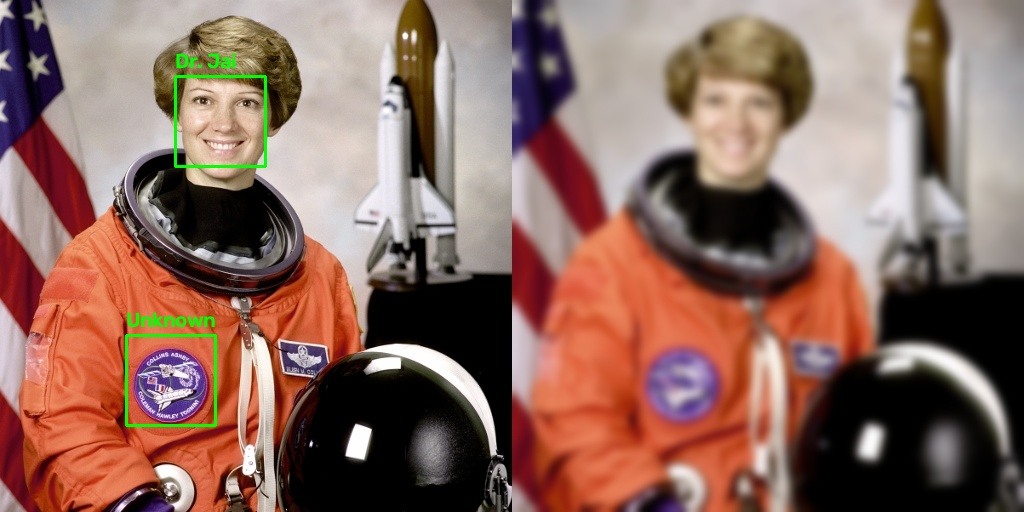

In [8]:
import os
import cv2
import numpy as np
import face_recognition
from google.colab import files
from IPython.display import Image, display

if not os.path.exists("known_person.jpg") or not os.path.exists("group_photo.jpg"):
    print("Click 'Choose Files' to select 2 photos, or click 'Cancel' to use built-in offline images:")
    uploaded = files.upload()
    uploaded_names = list(uploaded.keys())
    if len(uploaded_names) >= 2:
        first_file = uploaded_names.pop(0)
        second_file = uploaded_names.pop(0)
        if first_file != "known_person.jpg":
            os.rename(first_file, "known_person.jpg")
        if second_file != "group_photo.jpg":
            os.rename(second_file, "group_photo.jpg")
    else:
        from skimage import data
        person = data.astronaut()
        cv2.imwrite("known_person.jpg", cv2.cvtColor(person, cv2.COLOR_RGB2BGR))
        person_blurred = cv2.GaussianBlur(person, (25, 25), 0)
        group = np.hstack((person, person_blurred))
        cv2.imwrite("group_photo.jpg", cv2.cvtColor(group, cv2.COLOR_RGB2BGR))

known_img = face_recognition.load_image_file("known_person.jpg")
known_encodings = face_recognition.face_encodings(known_img)

if not known_encodings:
    raise ValueError("No face detected in known_person.jpg. Use a clearer front-facing photo.")

known_encoding = known_encodings.pop(0)
known_name = "Dr. Jai"

test_img = face_recognition.load_image_file("group_photo.jpg")
locations = face_recognition.face_locations(test_img)
encodings = face_recognition.face_encodings(test_img, locations)
print("Faces detected:", len(locations))

output = cv2.cvtColor(test_img, cv2.COLOR_RGB2BGR)

for (top, right, bottom, left), enc in zip(locations, encodings):
    distance = face_recognition.face_distance([known_encoding], enc).item()
    match = face_recognition.compare_faces([known_encoding], enc, tolerance=0.6).pop(0)
    name = known_name if match else "Unknown"

    print("Face at (top=%d, left=%d): %s (distance %.2f)" % (top, left, name, distance))

    cv2.rectangle(output, (left, top), (right, bottom), (0, 255, 0), 2)
    label_y = top - 8 if top - 8 > 15 else bottom + 20
    cv2.putText(output, name, (left, label_y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

cv2.imwrite("recognised.jpg", output)
print("Result saved as recognised.jpg")
display(Image("recognised.jpg"))
